# Push-T Behavior Cloning - Experiments

Training and evaluation of every experiment in [REPORT.md](../REPORT.md). The cheap runs (v0, E2, E3) ran on CPU; the
end-to-end encoder (E4, E7) and the pretrained Diffusion Policy ran on a Colab GPU and their outputs were copied into `runs/`.

Each section starts with a config cell. With its `TRAIN_*` / `EVAL_*` flags off, a section only loads the saved results
from `runs/`, so the whole notebook runs in a couple of minutes on CPU.

## 0. Setup

### 0.1 Environment

On Colab, the first cell clones the repo into `/content/push-t` (or pulls it) and the second installs it. Restart the
session after the first install.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/JuaniLlaberia/push-t.git"

if IN_COLAB:
    colab_dir = Path("/content/push-t")
    if not colab_dir.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(colab_dir)], check=True)
    else:
        subprocess.run(["git", "-C", str(colab_dir), "pull", "-q"], check=True)
    os.chdir(colab_dir)

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
print(f"Repo root: {ROOT} | Colab: {IN_COLAB}")

Repo root: D:\Code\push-t | Colab: False


In [2]:
if IN_COLAB:
    %pip install -q -e "{ROOT}[dev]"

### 0.2 Imports

In [3]:
import json

from IPython.display import Image, display

from pusht_bc.config import load_config, resolve_path
from pusht_bc.evaluate import build_agent_from_checkpoint, format_summary, run_and_save
from pusht_bc.train import save_train_outputs, train
from pusht_bc.utils import checkpoint_path, get_device, plot_losses, run_dir

DEVICE = get_device()
print(f"Device: {DEVICE}")

Device: cpu


### 0.3 Feature Cache

Frozen ResNet-18 features of every frame, used by v0, E2, E3 and the v0 chunking check. Built once (about 5 min on CPU).

In [4]:
cache = resolve_path("data/cache/features_resnet18.pt")
if not cache.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "cache_features.py")], cwd=ROOT, check=True)
print(f"Feature cache: {cache.relative_to(ROOT).as_posix()} (exists: {cache.exists()})")

Feature cache: data/cache/features_resnet18.pt (exists: True)


### 0.4 Helpers

In [5]:
def eval_checkpoint(ckpt_path, cfg, seeds=None, record_seeds=None, out_dir=None):
    """
    Evaluate a checkpoint closed loop and save summary.json, videos and the coverage plot.

    Args:
        ckpt_path: checkpoint file.
        cfg: Config of the run (seeds and max_steps come from cfg.eval unless given).
        seeds: env seeds (default: dev seeds 0-49).
        record_seeds: seeds to record as video (default: cfg.eval.record_seeds).
        out_dir: output folder (default: <run>/eval/<checkpoint name>).
    Returns:
        EvalSummary.
    """
    seeds = cfg.eval.dev_seed_list() if seeds is None else seeds
    record_seeds = cfg.eval.record_seeds if record_seeds is None else record_seeds
    ckpt_path = Path(ckpt_path)
    out_dir = out_dir or run_dir(cfg) / "eval" / ckpt_path.stem
    agent = build_agent_from_checkpoint(ckpt_path, DEVICE)
    summary = run_and_save(agent, seeds, record_seeds, out_dir, cfg.eval.max_steps, label=f"{cfg.name}/{ckpt_path.stem}")
    print(format_summary(summary, cfg.name))
    return summary

def show_results(out_dir, label):
    """
    Print a saved evaluation summary and show its coverage plot.

    Args:
        out_dir: folder with summary.json (and coverage.png if seeds were recorded).
        label: name to print.
    """
    out = resolve_path(out_dir)
    if not (out / "summary.json").exists():
        print(f"{label}: no results yet in {out.relative_to(ROOT).as_posix()}")
        return
    s = json.loads((out / "summary.json").read_text())
    seeds = [e["seed"] for e in s["episodes"]]
    print(
        f"{label}: success {s['success_rate']:.1%} (95% CI {s['ci_low']:.1%}-{s['ci_high']:.1%}), "
        f"avg max coverage {s['avg_max_coverage']:.3f} | seeds {seeds[0]}-{seeds[-1]} (n={s['n_episodes']})"
    )
    if (out / "coverage.png").exists():
        display(Image(str(out / "coverage.png"), width=560))

def show_training(cfg):
    """
    Print validation loss per epoch and show the loss curves of a run.

    Args:
        cfg: Config of the run.
    """
    hist = json.loads((run_dir(cfg) / "history.json").read_text())
    val = hist["history"]["val_loss"]
    best = min(range(len(val)), key=val.__getitem__)
    print(f"{cfg.name}: {len(val)} epochs, best val loss {val[best]:.5f} at epoch {best + 1}, last {val[-1]:.5f}")
    display(Image(str(plot_losses(hist["history"], run_dir(cfg) / "losses.png")), width=560))

---

## 1. Sanity Check: Pretrained Diffusion Policy

`lerobot/diffusion_pusht` through the same evaluation loop. Its model card reports 63.8-65.4% success over 500
episodes, so a score far from that would point to a bug in the loop, not in the policy. Needs a GPU.

In [6]:
RUN_DP = False

if RUN_DP:
    from pusht_bc.policies.pretrained_dp import PretrainedDiffusionAgent

    dp_agent = PretrainedDiffusionAgent(device=DEVICE)
    dp_summary = run_and_save(dp_agent, list(range(50)), [0, 1, 2], "runs/diffusion_pusht/eval", 300, label="diffusion_pusht")

Diffusion Policy: success 58.0% (95% CI 44.2%-70.6%), avg max coverage 0.909 | seeds 0-49 (n=50)


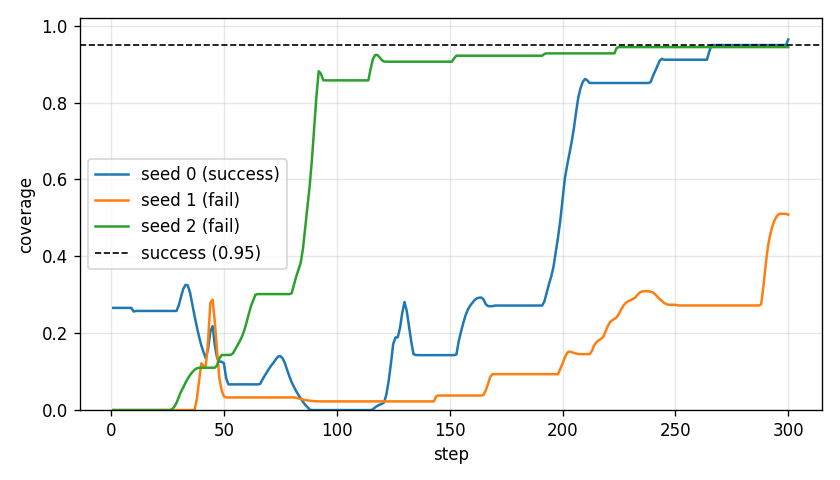

In [7]:
show_results("runs/diffusion_pusht/eval", "Diffusion Policy")

**Result:** 58% on seeds 0-49 (95% CI 44-71%), consistent with the model card, so the loop is trusted. A first run
scored 84%: gym-pusht's reward is `clip(coverage / 0.95, 0, 1)`, not the coverage, so near misses counted as successes.
The loop now reads `info["coverage"]`.

---

## 2. E1. Plain Behavior Cloning (v0)

Frozen ImageNet ResNet-18 features (cached) + pusher position → MLP → next target position, MSE on normalized actions.
AdamW, lr 1e-3, batch 256, 50 epochs.

**Prediction:** around 25% success: it does something, but little with so few demonstrations (written after the run).

In [8]:
CONFIG_E1 = ROOT / "configs/bc_v0.yaml"
TRAIN_E1 = False
EVAL_E1 = False

cfg_E1 = load_config(CONFIG_E1)

In [9]:
if TRAIN_E1:
    save_train_outputs(cfg_E1, train(cfg_E1))
if EVAL_E1:
    eval_checkpoint(checkpoint_path(cfg_E1, cfg_E1.epochs), cfg_E1)

bc_v0: 50 epochs, best val loss 0.00557 at epoch 44, last 0.00584


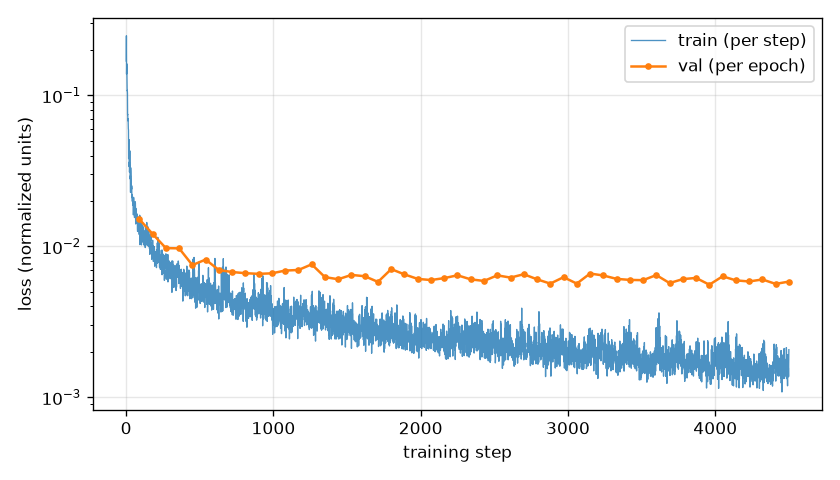

v0: success 0.0% (95% CI 0.0%-7.1%), avg max coverage 0.098 | seeds 0-49 (n=50)


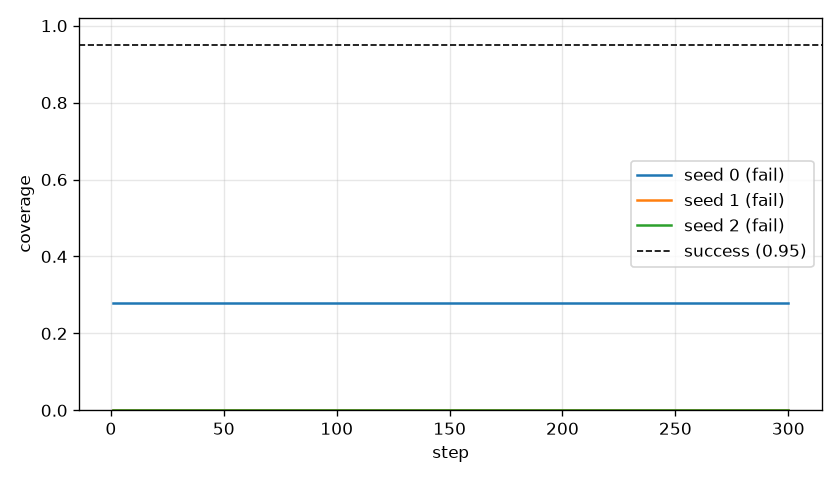

In [10]:
show_training(cfg_E1)
show_results(run_dir(cfg_E1) / "eval/epoch_050", "v0")

**Result:** 0% success, avg max coverage 0.098. The pusher moves for 20-40 steps, then parks near one spot and often
never touches the T. On held-out episodes the model barely beats "output the current pusher position" (MSE 0.0059 vs.
0.0069), while on training episodes it is 4.5× better: the frozen features let it memorize, not generalize.

---

## 3. E2. Validation Loss vs. Closed-Loop Performance

The v0 checkpoints from epochs 5, 10, 25 and 50, each evaluated on seeds 0-49.

In [11]:
E2_EPOCHS = [5, 10, 25, 50]
EVAL_E2 = False

if EVAL_E2:
    for ep in E2_EPOCHS:
        eval_checkpoint(checkpoint_path(cfg_E1, ep), cfg_E1, record_seeds=[])

Epoch 5: val loss 0.00752, success 0%, avg max coverage 0.093
Epoch 10: val loss 0.00658, success 0%, avg max coverage 0.098
Epoch 25: val loss 0.00643, success 0%, avg max coverage 0.115
Epoch 50: val loss 0.00584, success 0%, avg max coverage 0.098


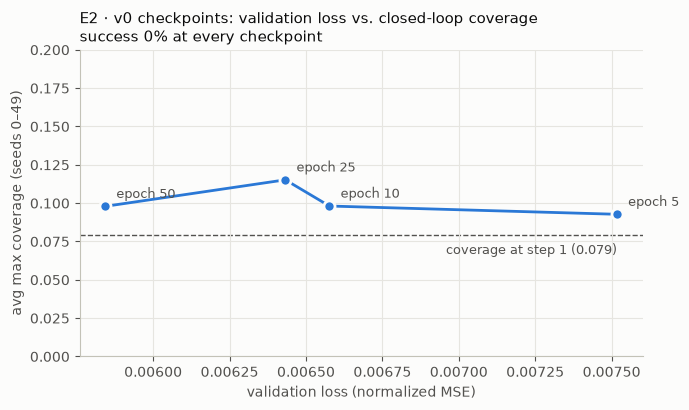

In [12]:
import matplotlib.pyplot as plt

hist_E2 = json.loads((run_dir(cfg_E1) / "history.json").read_text())["history"]
evals_E2 = {ep: json.loads((run_dir(cfg_E1) / f"eval/epoch_{ep:03d}/summary.json").read_text()) for ep in E2_EPOCHS}
val_loss_E2 = {ep: hist_E2["val_loss"][ep - 1] for ep in E2_EPOCHS}
cov_E2 = {ep: evals_E2[ep]["avg_max_coverage"] for ep in E2_EPOCHS}
last_eps = evals_E2[E2_EPOCHS[-1]]["episodes"]
start_cov_E2 = sum(e["rewards"][0] for e in last_eps) / len(last_eps)

for ep in E2_EPOCHS:
    print(f"Epoch {ep}: val loss {val_loss_E2[ep]:.5f}, success {evals_E2[ep]['success_rate']:.0%}, avg max coverage {cov_E2[ep]:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.2), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
xs = [val_loss_E2[ep] for ep in E2_EPOCHS]
ys = [cov_E2[ep] for ep in E2_EPOCHS]
ax.plot(xs, ys, color="#2a78d6", linewidth=2, zorder=2)
ax.scatter(xs, ys, s=64, color="#2a78d6", edgecolors="#fcfcfb", linewidths=2, zorder=3)
for ep, x, y in zip(E2_EPOCHS, xs, ys):
    ax.annotate(f"epoch {ep}", (x, y), textcoords="offset points", xytext=(8, 6), fontsize=9, color="#52514e")
ax.axhline(start_cov_E2, color="#52514e", linestyle="--", linewidth=1, zorder=1)
ax.annotate(f"coverage at step 1 ({start_cov_E2:.3f})", (max(xs), start_cov_E2), textcoords="offset points",
            xytext=(0, -14), ha="right", fontsize=9, color="#52514e")
ax.set_ylim(0, max(0.2, max(ys) * 1.4))
ax.set_xlabel("validation loss (normalized MSE)", color="#52514e")
ax.set_ylabel("avg max coverage (seeds 0–49)", color="#52514e")
ax.set_title("E2 · v0 checkpoints: validation loss vs. closed-loop coverage\nsuccess 0% at every checkpoint",
             loc="left", fontsize=11, color="#0b0b0b")
ax.grid(color="#e6e5e0", linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
fig.tight_layout()
fig.savefig(run_dir(cfg_E1) / "e2_val_vs_coverage.png", dpi=150)
plt.show()

**Result:** validation loss fell by 22% from epoch 5 to epoch 50 while coverage stayed within a few points of doing
nothing. Offline loss measures error on states the expert visited, not on the states the policy drives itself into,
so it doesn't predict closed-loop performance.

---

## 4. E3. Data Quantity

v0 trained on 25% and 50% of the training episodes (same validation split). `scripts/run_e3.py` trains both and
evaluates them on seeds 0-49.

In [13]:
RUN_E3 = False

if RUN_E3:
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_e3.py")], cwd=ROOT, check=True)

for r in json.loads(resolve_path("runs/e3_summary.json").read_text()):
    print(f"{r['name']:<12} {r['fraction']:.0%} of episodes | best val loss {r['best_val_loss']:.5f} | "
          f"success {r['success_rate']:.0%} | avg max coverage {r['avg_max_coverage']:.3f}")

e3_frac25    25% of episodes | best val loss 0.00954 | success 0% | avg max coverage 0.110
e3_frac50    50% of episodes | best val loss 0.00665 | success 0% | avg max coverage 0.123
bc_v0        100% of episodes | best val loss 0.00557 | success 0% | avg max coverage 0.098


**Result:** validation loss improves steadily with more data (0.0095 → 0.0067 → 0.0056), but coverage stays at
0.10-0.12 with no trend. More of the same data doesn't help when the frozen features can't see the T well.

---

## 5. E4. End-to-End Encoder

ResNet-18 trained end to end on random 84×84 crops (center crop at evaluation), lr 1e-4, batch 64, 20 epochs.
Trained and evaluated on a Colab T4 (10-15 min of training).

In [14]:
CONFIG_E4 = ROOT / "configs/e4_end_to_end.yaml"
TRAIN_E4 = False
EVAL_E4 = False

cfg_E4 = load_config(CONFIG_E4)

In [15]:
if TRAIN_E4:
    save_train_outputs(cfg_E4, train(cfg_E4))
if EVAL_E4:
    eval_checkpoint(checkpoint_path(cfg_E4, cfg_E4.epochs), cfg_E4)

e4_end_to_end: 20 epochs, best val loss 0.00418 at epoch 7, last 0.00424


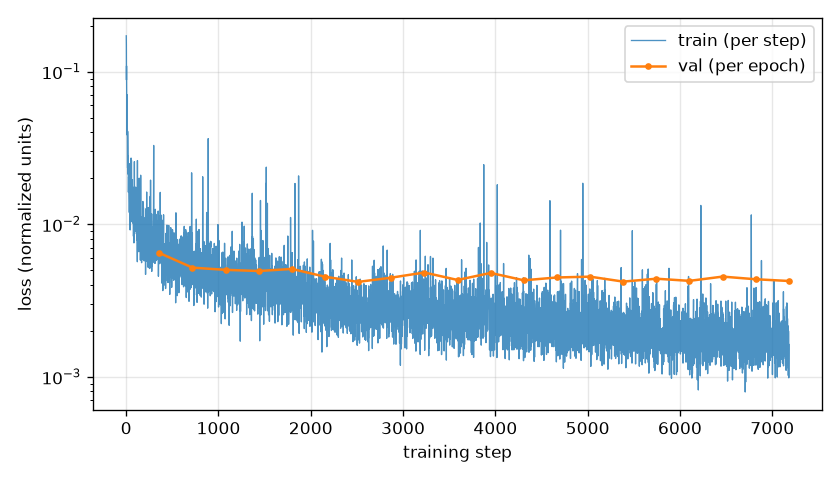

E4: success 0.0% (95% CI 0.0%-7.1%), avg max coverage 0.290 | seeds 0-49 (n=50)


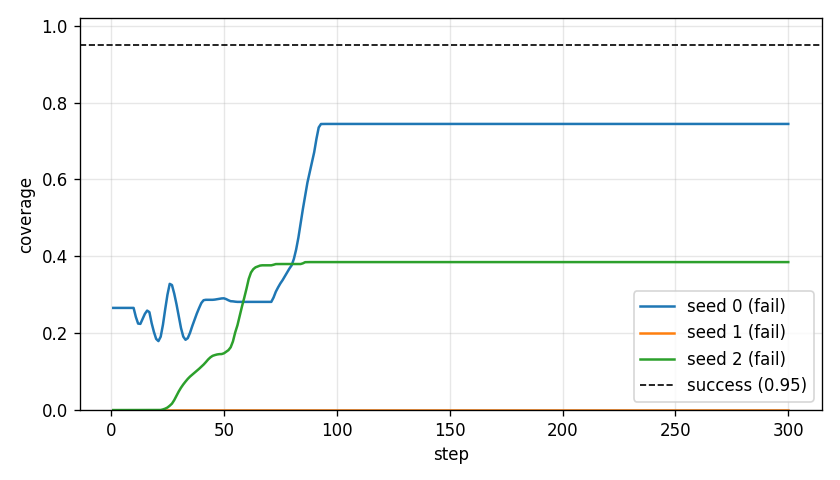

In [16]:
show_training(cfg_E4)
show_results(run_dir(cfg_E4) / "eval/epoch_020", "E4")

**Result:** still 0% success, but 3× v0's coverage (0.290 vs. 0.098). E4 actually pushes the T, and 5 of 50 seeds
reach 0.90-0.94 coverage. Validation loss plateaus around 0.0042-0.0045 from epoch 7.

---

## 6. E7. Action Chunking

The policy predicts the next 8 actions at once and executes 4 before predicting again, so it commits to a short plan
instead of re-deciding every step. Padded targets past the end of an episode are masked out of the loss.

- **Local check:** v0 + chunking on CPU, to verify the code end to end.
- **Experiment:** E4 + chunking on a Colab GPU, with every other setting identical to E4. Runs automatically on Colab.

v0 + chunking: success 0.0% (95% CI 0.0%-7.1%), avg max coverage 0.221 | seeds 0-49 (n=50)


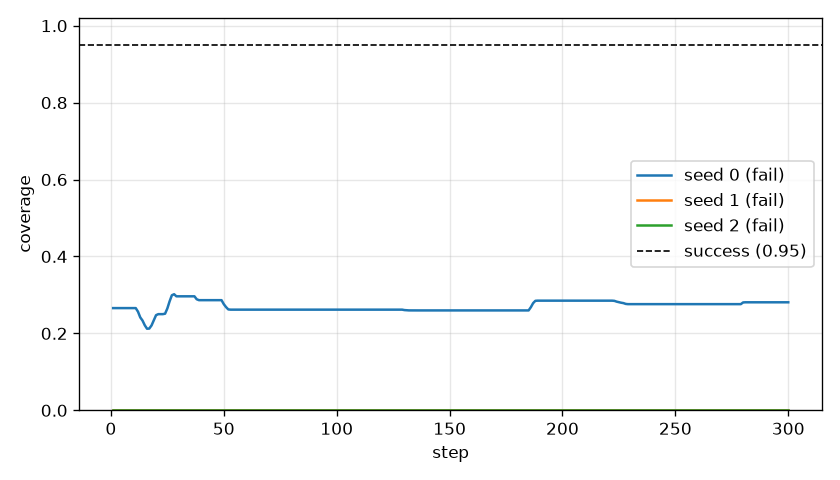

In [17]:
cfg_E7_v0 = load_config(ROOT / "configs/e7_chunk_v0.yaml")
show_results(run_dir(cfg_E7_v0) / "eval/epoch_050", "v0 + chunking")

**Local check:** still 0% success, but coverage more than doubles over v0 (0.221 vs. 0.098) and 21 of 50 episodes
gain more than 5 points of coverage (v0: 6). Chunking works and already helps with the weak frozen features.

In [18]:
CONFIG_E7 = ROOT / "configs/e7_chunk_e4.yaml"
TRAIN_E7 = IN_COLAB
EVAL_E7 = IN_COLAB

cfg_E7 = load_config(CONFIG_E7)

In [19]:
if TRAIN_E7:
    save_train_outputs(cfg_E7, train(cfg_E7))
if EVAL_E7:
    eval_checkpoint(checkpoint_path(cfg_E7, cfg_E7.epochs), cfg_E7)
    eval_checkpoint(checkpoint_path(cfg_E7, cfg_E7.epochs), cfg_E7, seeds=list(range(1000, 1200)), record_seeds=[],
                    out_dir=run_dir(cfg_E7) / "eval/final_epoch_020")

Colab T4 run:
epoch 1/20 | train 0.0253 | val 0.0175
epoch 2/20 | train 0.0128 | val 0.0163
epoch 3/20 | train 0.0101 | val 0.0172
epoch 4/20 | train 0.0085 | val 0.0155
epoch 5/20 | train 0.0076 | val 0.0166
epoch 6/20 | train 0.0068 | val 0.0155
epoch 7/20 | train 0.0058 | val 0.0163
epoch 8/20 | train 0.0055 | val 0.0164
epoch 9/20 | train 0.0052 | val 0.0156
epoch 10/20 | train 0.0049 | val 0.0159
epoch 11/20 | train 0.0046 | val 0.0165
epoch 12/20 | train 0.0044 | val 0.0158
epoch 13/20 | train 0.0043 | val 0.0174
epoch 14/20 | train 0.0041 | val 0.0164
epoch 15/20 | train 0.0038 | val 0.0159
epoch 16/20 | train 0.0036 | val 0.0157
epoch 17/20 | train 0.0034 | val 0.0161
epoch 18/20 | train 0.0035 | val 0.0159
epoch 19/20 | train 0.0032 | val 0.0168
epoch 20/20 | train 0.0034 | val 0.0160
e7_chunk_e4: success 12.0% (95% CI 5.6%-23.8%, n=50), avg max coverage 0.643
e7_chunk_e4: success 9.5% (95% CI 6.2%-14.4%, n=200), avg max coverage 0.551


In [20]:
if IN_COLAB:
    import shutil
    from google.colab import files

    export = Path("/content/e7_export") / "runs" / cfg_E7.name
    shutil.copytree(run_dir(cfg_E7) / "eval", export / "eval", dirs_exist_ok=True)
    for f in ["history.json", "losses.png", f"checkpoints/epoch_{cfg_E7.epochs:03d}.pt"]:
        (export / f).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(run_dir(cfg_E7) / f, export / f)
    files.download(shutil.make_archive("/content/e7_results", "zip", "/content/e7_export"))

e7_chunk_e4: 20 epochs, best val loss 0.01550 at epoch 6, last 0.01599


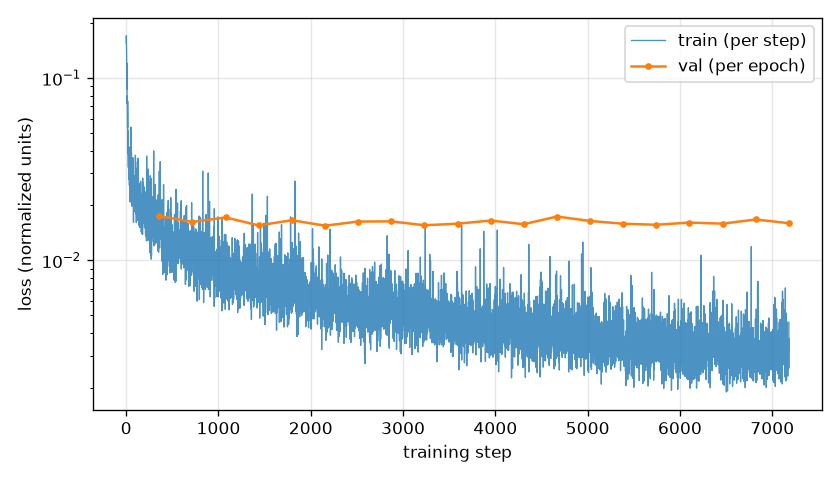

E4 + chunking: success 12.0% (95% CI 5.6%-23.8%), avg max coverage 0.643 | seeds 0-49 (n=50)


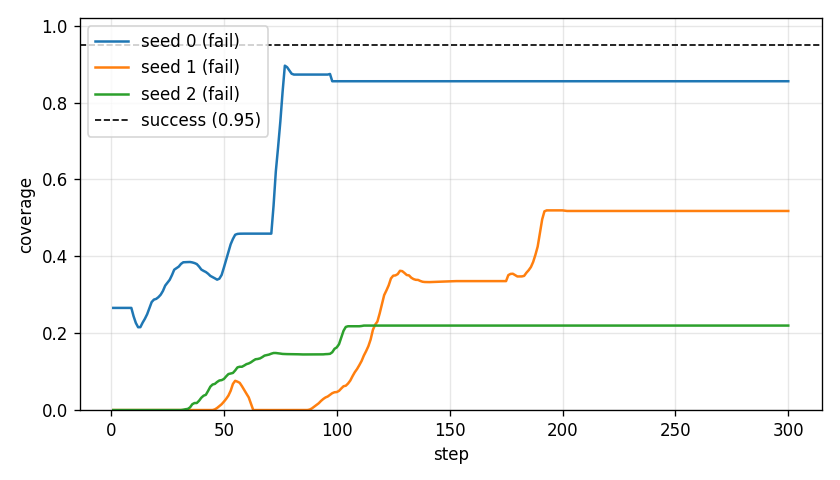

In [21]:
if (run_dir(cfg_E7) / "history.json").exists():
    show_training(cfg_E7)
show_results(run_dir(cfg_E7) / "eval/epoch_020", "E4 + chunking")

**Result:** the first behavior-cloning successes: 12% on seeds 0-49 (6/50) and 9.5% on the final seeds (95% CI
6.2-14.4%). Coverage on seeds 0-49 more than doubles over E4 (0.643 vs. 0.290). The validation loss (about 0.016)
averages the error over 8 future actions, so it is not comparable with the single-action runs.

---

## 7. Final Evaluation (seeds 1000-1199)

Fresh seeds, used only for the final numbers. Run with `python -m pusht_bc.evaluate --checkpoint <run>/checkpoints/<epoch>.pt
--seeds 1000-1199` (and `--pretrained-dp` for the Diffusion Policy, on a GPU).

In [22]:
FINAL = {
    "Diffusion Policy": "runs/diffusion_pusht/eval_final",
    "BC v0": "runs/bc_v0/eval/final_epoch_050",
    "BC E4": "runs/e4_end_to_end/eval/final_epoch_020",
    "BC E4 + chunking": "runs/e7_chunk_e4/eval/final_epoch_020",
}

for label, folder in FINAL.items():
    show_results(folder, label)

Diffusion Policy: success 60.0% (95% CI 53.1%-66.5%), avg max coverage 0.896 | seeds 1000-1199 (n=200)
BC v0: success 0.0% (95% CI 0.0%-1.9%), avg max coverage 0.099 | seeds 1000-1199 (n=200)
BC E4: success 0.0% (95% CI 0.0%-1.9%), avg max coverage 0.258 | seeds 1000-1199 (n=200)
BC E4 + chunking: success 9.5% (95% CI 6.2%-14.4%), avg max coverage 0.551 | seeds 1000-1199 (n=200)


**Result:** the Diffusion Policy solves 60% of the fresh seeds, behavior cloning with action chunking 9.5%, and
single-step behavior cloning none. See [REPORT.md](../REPORT.md) for the failure analysis.